# Problem 3.4

Reproduce a plot similar to the one shown in Fig. 3.10 for

$$f(x) = \cos(x) + 1$$

in the neighborhood of $x = \pi$.

In [29]:
%reset -f
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

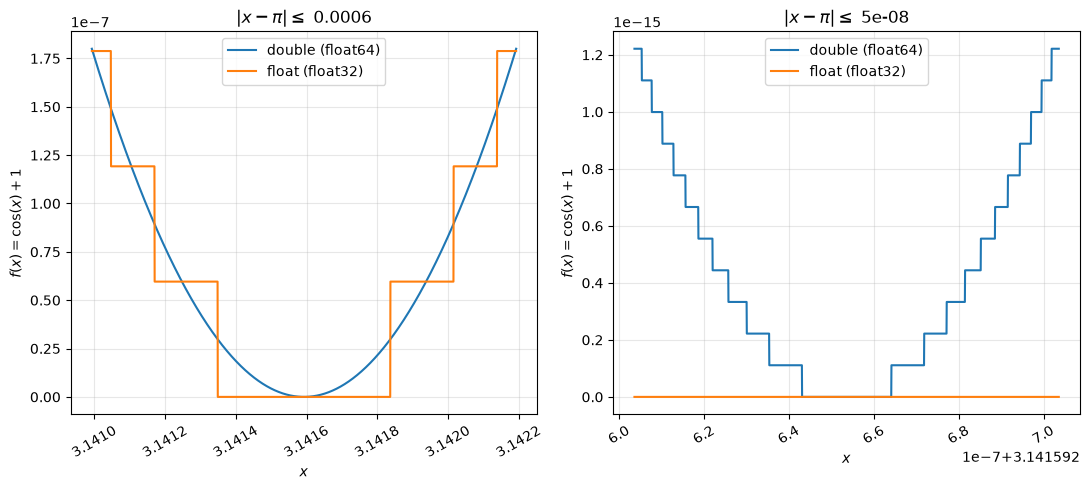

In [30]:
def func(x):
    return np.cos(x) + 1

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, half_width in zip(axes, [6e-4, 5e-8]): # two plots with different x ranges (one shows the steps of float32, the other shows the steps of float64)
    x = np.pi + np.linspace(-half_width, half_width, 4000)

    ax.plot(x, func(x), "-", label="double (float64)")                    # plot as double
    ax.plot(x, func(x.astype(np.float32)), "-", label="float (float32)")  # plot as float32
    ax.set_title(f"$|x-\\pi| \\leq$ {half_width:g}")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$f(x) = \\cos(x) + 1$")
    ax.grid(alpha=0.3)
    ax.legend()
    ax.tick_params(axis="x", labelrotation=30)

plt.tight_layout()
plt.show()

## Results

the stepping behavor of the float numbers as seem in the book is also visible here. the result of the function at pi is zero which is the case for both numer types here (float and double). but the float is also zero near pi in a range of roughly +-0.00025 around pi. each step is 6*e-8 units high so in the curent plot there are 6 steps visible. 3 on each side of pi. in the second plot we can see the same behavior of the double numbers. form the labels we can see that we are much more zoomed in. the float is a flat line at zero here.

## Interpretation

floating point numbers are not a good choice when a low noise level is needed for the calculation. for example if the convergence tolerance tolerance of a optimizer is below the step size of the float. double also has a step size but it is about 9 magnitudes smaller than that of the float. floats should be used with caution in optimization runs.